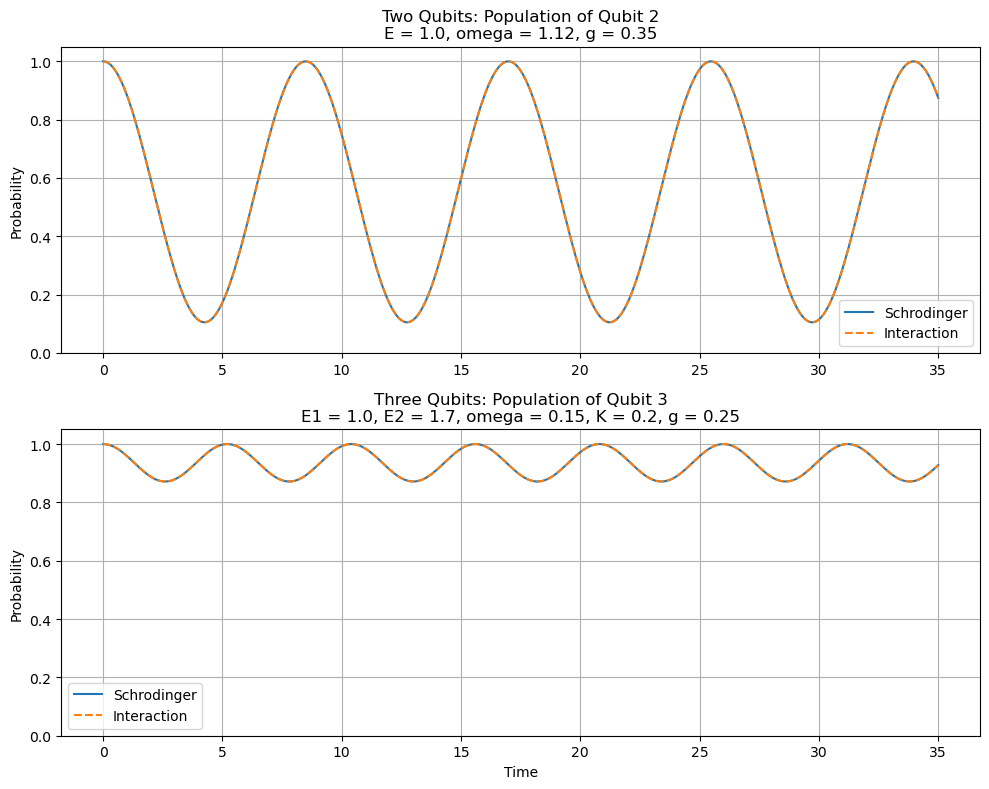

Two-qubit maximum difference: 4.440892098500626e-16
Three-qubit maximum difference: 3.3306690738754696e-16


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

# Common single-qubit operators (hbar = 1)
I = np.eye(2, dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
plus = np.array([[0, 1], [0, 0]], dtype=complex)
minus = plus.conj().T

P1 = np.array([[0, 0], [0, 1]], dtype=complex)

zero = np.array([1, 0], dtype=complex)
one = np.array([0, 1], dtype=complex)

k3 = lambda A, B, C: np.kron(np.kron(A, B), C)
times = np.linspace(0, 35, 351)


# =======================================
# PROBLEM 1: TWO QUBITS
# =======================================

# Measurement operator
M2 = np.kron(I, P1)

# Constants
E, omega, g = 1.0, 1.12, 0.35

# Total Hamiltonian
H2 = (E*np.kron(Z, I) + omega*np.kron(I, Z)
      + g*(np.kron(minus, plus) + np.kron(plus, minus)))

# Initial state |01>
psi0_2 = np.kron(zero, one)

# Free Hamiltonian and interaction
H0_2 = E*np.kron(Z, I) + omega*np.kron(I, Z)
V2 = H2 - H0_2

prob_S2, prob_I2 = [], []

for t in times:

    # Schrodinger picture
    psi_S = expm(-1j*H2*t) @ psi0_2
    prob_S2.append(np.vdot(psi_S, M2 @ psi_S).real)

    # Interaction picture
    U0 = expm(-1j*H0_2*t)
    psi_I = U0.conj().T @ psi_S
    M_I = U0.conj().T @ M2 @ U0

    prob_I2.append(np.vdot(psi_I, M_I @ psi_I).real)


# =======================================
# PROBLEM 2: THREE QUBITS
# =======================================

# Measurement operator
M3 = k3(I, I, P1)

# Constants
E1, E2, omega3, K, g3 = 1.0, 1.7, 0.15, 0.2, 0.25
# Total Hamiltonian
H3 = (E1*k3(Z,I,I) + E2*k3(I,Z,I)
      + omega3*k3(I,I,Z)
      + K*k3(Z,Z,I)
      + g3*(k3(minus,plus,minus) + k3(plus,minus,plus)))

# Initial state, as written in the assignment
# Normalize (sqrt(3)/2 |10> + 1/2 |10>) x |1>
psi0_3 = (np.sqrt(3)/2 * k3(one, zero, one)
          + 1/2 * k3(zero, one, one))
psi0_3 = psi0_3 / np.linalg.norm(psi0_3)

# If the second term was intended to be |01>, use:
# psi0_3 = (np.sqrt(3)/2*k3(one,zero,one)
#           + 1/2*k3(zero,one,one))

# Free Hamiltonian and interaction
H0_3 = (E1*k3(Z,I,I) + E2*k3(I,Z,I)
        + omega3*k3(I,I,Z))
V3 = H3 - H0_3

prob_S3, prob_I3 = [], []

for t in times:

    # Schrodinger picture
    psi_S = expm(-1j*H3*t) @ psi0_3
    prob_S3.append(np.vdot(psi_S, M3 @ psi_S).real)

    # Interaction picture
    U0 = expm(-1j*H0_3*t)
    psi_I = U0.conj().T @ psi_S
    M_I = U0.conj().T @ M3 @ U0

    prob_I3.append(np.vdot(psi_I, M_I @ psi_I).real)


# =======================================
# COMPARE RESULTS AND PLOT
# =======================================

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

# Two-qubit problem
axes[0].plot(times, prob_S2, label="Schrodinger")
axes[0].plot(times, prob_I2, "--", label="Interaction")

axes[0].set_title(
    f"Two Qubits: Population of Qubit 2\n"
    f"E = {E}, omega = {omega}, g = {g}"
)

# Three-qubit problem
axes[1].plot(times, prob_S3, label="Schrodinger")
axes[1].plot(times, prob_I3, "--", label="Interaction")

axes[1].set_title(
    f"Three Qubits: Population of Qubit 3\n"
    f"E1 = {E1}, E2 = {E2}, omega = {omega3}, "
    f"K = {K}, g = {g3}"
)

for ax in axes:
    ax.set_ylabel("Probability")
    ax.set_ylim(0, 1.05)
    ax.grid(True)
    ax.legend()

axes[1].set_xlabel("Time")

plt.tight_layout()
plt.show()

# Numerical comparison
print("Two-qubit maximum difference:",
      np.max(np.abs(np.array(prob_S2) - np.array(prob_I2))))

print("Three-qubit maximum difference:",
      np.max(np.abs(np.array(prob_S3) - np.array(prob_I3))))


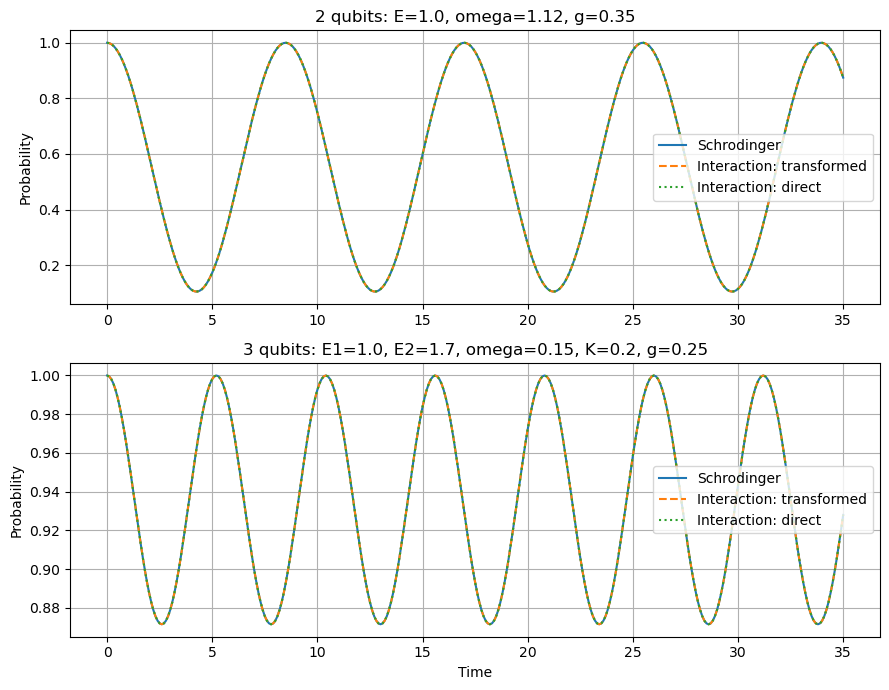

2-qubit direct error: 5.159351834649328e-10
3-qubit direct error: 1.3860501635321043e-10


In [2]:

from scipy.integrate import solve_ivp

# Solve the interaction picture directly
def direct_interaction(H0, V, psi0, M, times):

    def equation(t, psi_I):
        U0 = expm(-1j * H0 * t)
        VI = U0.conj().T @ V @ U0
        return -1j * VI @ psi_I

    solution = solve_ivp(
        equation, (times[0], times[-1]), psi0,
        t_eval=times, rtol=1e-10, atol=1e-12
    )

    probabilities = []

    for t, psi_I in zip(times, solution.y.T):
        U0 = expm(-1j * H0 * t)
        MI = U0.conj().T @ M @ U0
        p = np.vdot(psi_I, MI @ psi_I).real
        probabilities.append(p)

    return np.array(probabilities)


# Two-qubit system
p2_direct = direct_interaction(
    H0_2, V2, psi0_2, M2, times
)

# Three-qubit system
p3_direct = direct_interaction(
    H0_3, V3, psi0_3, M3, times
)


# Compare all three calculations
fig, axes = plt.subplots(2, 1, figsize=(9, 7))

for ax, pS, pI, pD, title in [
    (axes[0], prob_S2, prob_I2, p2_direct,
     f"2 qubits: E={E}, omega={omega}, g={g}"),
    (axes[1], prob_S3, prob_I3, p3_direct,
     f"3 qubits: E1={E1}, E2={E2}, "
     f"omega={omega3}, K={K}, g={g3}")
]:
    ax.plot(times, pS, label="Schrodinger")
    ax.plot(times, pI, "--", label="Interaction: transformed")
    ax.plot(times, pD, ":", label="Interaction: direct")
    ax.set_title(title)
    ax.set_ylabel("Probability")
    ax.grid(True)
    ax.legend()

axes[1].set_xlabel("Time")
plt.tight_layout()
plt.show()

print("2-qubit direct error:",
      np.max(np.abs(np.array(prob_S2) - p2_direct)))
print("3-qubit direct error:",
      np.max(np.abs(np.array(prob_S3) - p3_direct)))
